# External reference identity and manual annotation

This notebook reviews the decoded source datasets and the provisional anatomical mask. Its purpose is to check pixel identity and visible contours before any model receives a segmentation score.

## Introduction

### Assumptions

External data are evaluation-only. The expert H&E illustration has been manually digitized; its mask is provisional, and H&E-to-MSI registration is unavailable. Source assay representations require separate encoder compatibility checks.

### Notation

N denotes source pixels; M denotes source features. H and W are image height and width. H&E image index is yW+x, independently of MSI serialized row identity.

In [1]:
from pathlib import Path
from IPython.display import Image, Markdown, display
from msi_autoencoder_wrapper.analysis.autoencoder.experiments.reference_validation_precompute import load_settings, load_table, run_command

SETTINGS_PATH = Path("analysis_settings.yaml")
if not SETTINGS_PATH.is_file():
    SETTINGS_PATH = Path("assets/experiments/autoencoder_architecture/notebooks/agent_analysis_validation/analysis_settings.yaml")
settings = load_settings(SETTINGS_PATH)
results = Path(settings["output"])
print(run_command(SETTINGS_PATH, "datasets"))
print(run_command(SETTINGS_PATH, "demo"))

2026-10-13 22:16:06,305 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 1 implementation module(s) in package 'msi_autoencoder_wrapper.binners.binners_strategies'.


2026-10-13 22:16:06,308 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 6 implementation module(s) in package 'msi_autoencoder_wrapper.binners.inverse_strategies'.


/home/max/repositories/MSIAutoEncoderWrapper/.venv/bin/python -m msi_autoencoder_wrapper.analysis.autoencoder.experiments.reference_validation_precompute --settings /home/max/repositories/MSIAutoEncoderWrapper/assets/experiments/autoencoder_architecture/notebooks/agent_analysis_validation/analysis_settings.yaml --analysis datasets
/home/max/repositories/MSIAutoEncoderWrapper/.venv/bin/python -m msi_autoencoder_wrapper.analysis.autoencoder.experiments.reference_validation_precompute --settings /home/max/repositories/MSIAutoEncoderWrapper/assets/experiments/autoencoder_architecture/notebooks/agent_analysis_validation/analysis_settings.yaml --analysis demo


## Source identity and annotation coverage

### Methodology

#### Theoretical

An annotation is a map from a source pixel key to one disjoint class ID or unavailable (-1). Missing annotation is not a healthy/background label. Coverage is the number of available reference labels divided by N.

#### Implementation

The CLI decodes each source release once, validates shape/finite values and pixel identities, and writes checksummed memory-mapped arrays under data/. This notebook reads dataset_inventory.csv without decoding R files or loading models. Cardinal labels are diagnostic normal/cancer; the selected BlockSAM sample is normal-only. Poseidon uses the authors' positional row contract, preserving original row names.

#### Figure descriptions

The inventory table records pixels/features, available labels, source representation and coordinate units. It establishes source structure, not model input compatibility.

### Remarks

One normal-only sample cannot validate discrimination between cancer and normal tissue.

### Notes

In [2]:
display(load_table(settings, "dataset_inventory.csv"))

,dataset_id,image_id,pixels,features,reference_pixels,representation,coordinate_units,input_compatibility,cache
0,poseidon_ccrcc,ccrcc_section_1,4123,54,0,selected_transformed_features,source_grid,not_approved,data/kidney_segmentation_reference/decoded_cac...
1,cardinal_rcc,MH0204_33,1560,10200,811,source_binned_intensity,source_grid,not_approved,data/kidney_segmentation_reference/decoded_cac...
2,blocksam_kidney,NL_0705A190c,716,613,716,source_filtered_tic_features,unconfirmed_source_units,not_approved,data/kidney_segmentation_reference/decoded_cac...


## Disjoint manual annotation

### Methodology

#### Theoretical

Visible expert contours define six reviewable region classes. Polygon interiors are sampled at pixel centres. Conflicting classes and a three-pixel contour band remain unknown. No unseen tissue is classified from appearance.

#### Implementation

Explicit traced vertices reside in poseidon_regions.json. They are scaled to the original 1304×2032 image, rasterized and saved with original row-major image indices, vocabulary, provenance and SHA-256. The numeric NPZ is lossless; JPEG is presentation only. MSI projection refuses registration whose status is not accepted.

#### Figure descriptions

The left panel shows the original expert illustration; the right shows the six disjoint digitized classes in the same image coordinates. X/Y are H&E image pixels, Y increases downwards. The legend lists numeric IDs and colours. Dark grey means unknown/unannotated, including the uncertainty band. This is not an MSI pixel overlay.

### Remarks

The trace requires visual review and independent registration before anatomical MSI scoring.

### Notes

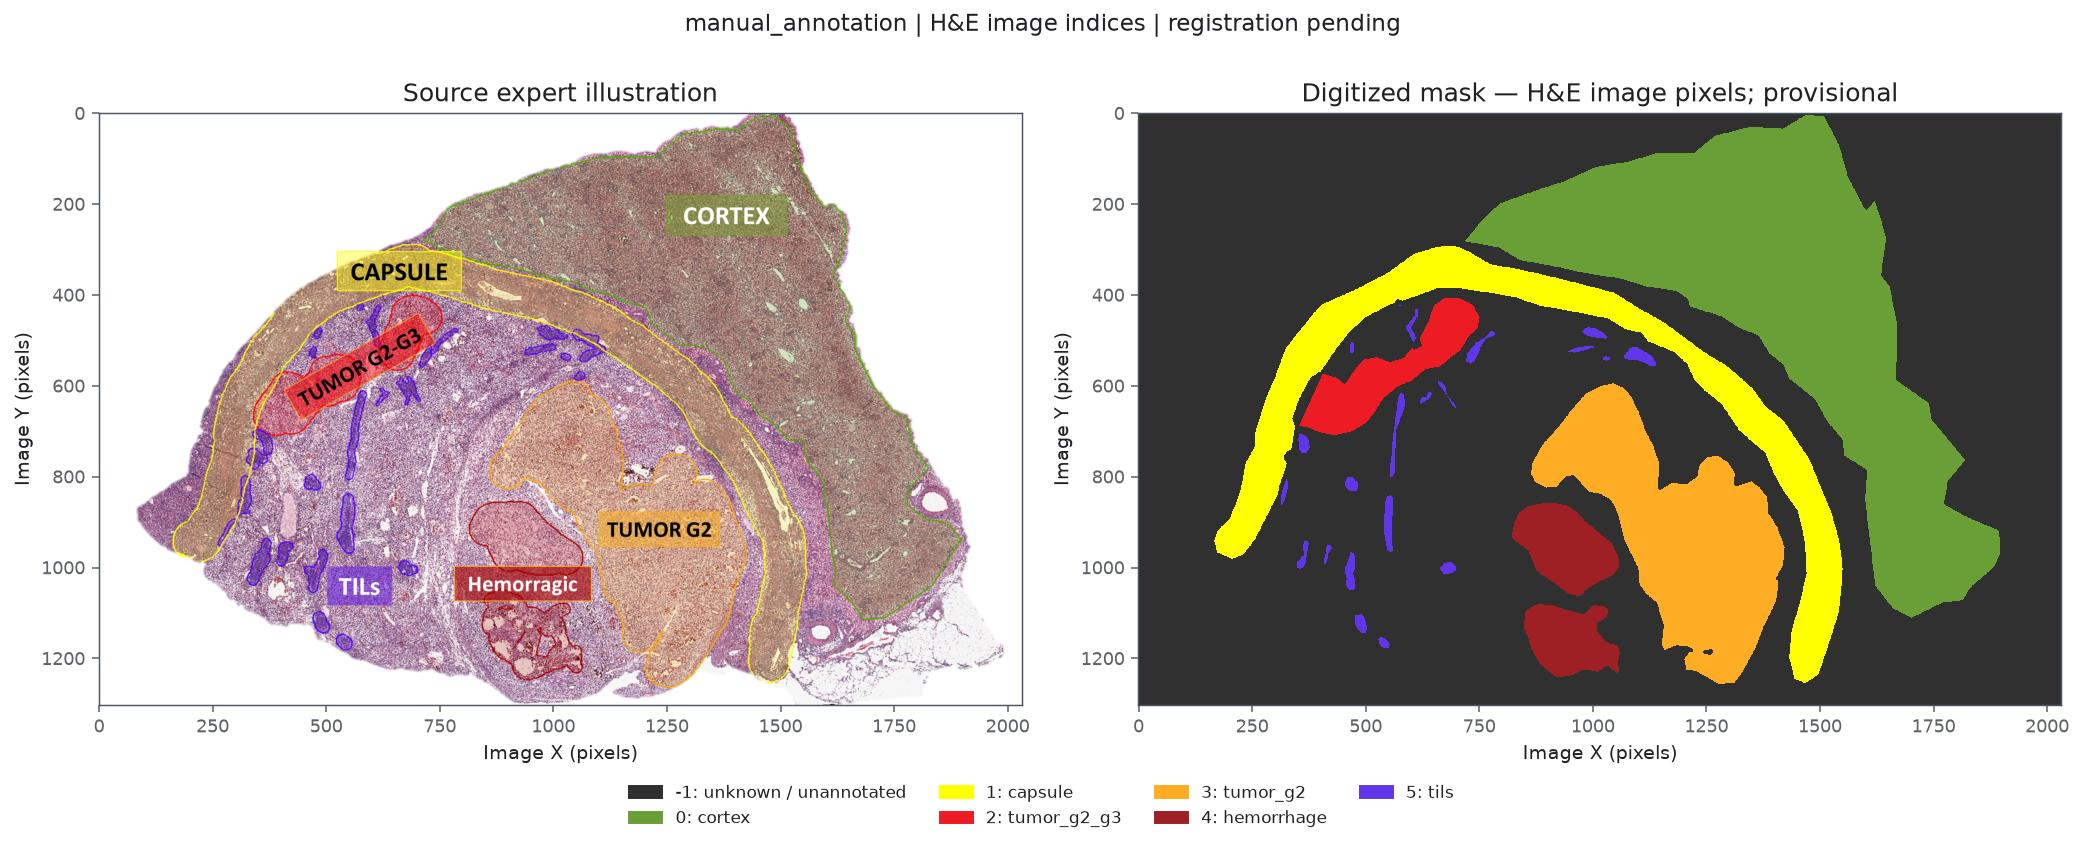

,class_id,class_name,pixels
0,0,cortex,416475
1,1,capsule,163112
2,2,tumor_g2_g3,38890
3,3,tumor_g2,164636
4,4,hemorrhage,54889
5,5,tils,15884


In [3]:
PREVIEW_NAME = "manual_annotation_comparison.jpeg"
display(Image(filename=str(results / "plots" / PREVIEW_NAME)))
display(load_table(settings, "manual_annotation_counts.csv"))

## Available external MSI masks

### Methodology

#### Theoretical

A diagnostic source mask is joined to the original source spectrum index. Normal/cancer labels differ from detailed anatomical classes. Unavailable pixels are explicitly unknown; they are not background or normal tissue.

#### Implementation

The dataset script produces one JPEG per selected acquisition, saved both under the canonical plots/ folder and each dataset's reference/ folder. The left panel shows the observed feature nearest the fixed requested m/z=750; the actual m/z is printed. The right panel shows source labels at the identical native coordinates. No normalization, registration or model prediction is fitted for this preview.

#### Figure descriptions

Both X/Y axes are native source coordinates with unconfirmed physical units. The intensity colourbar describes measured source values. The mask legend lists numeric IDs, names and pixel counts. Cardinal MH0204_33 includes cancer, normal and unknown pixels. The selected BlockSAM image NL_0705A190c contains only Normal. Poseidon has no numeric MSI mask yet; its anatomical H&E digitization is shown separately above.

### Remarks

The BlockSAM preview cannot establish cancer/normal discrimination. Source grids are not assumed registered to histology.

### Notes

### poseidon_ccrcc

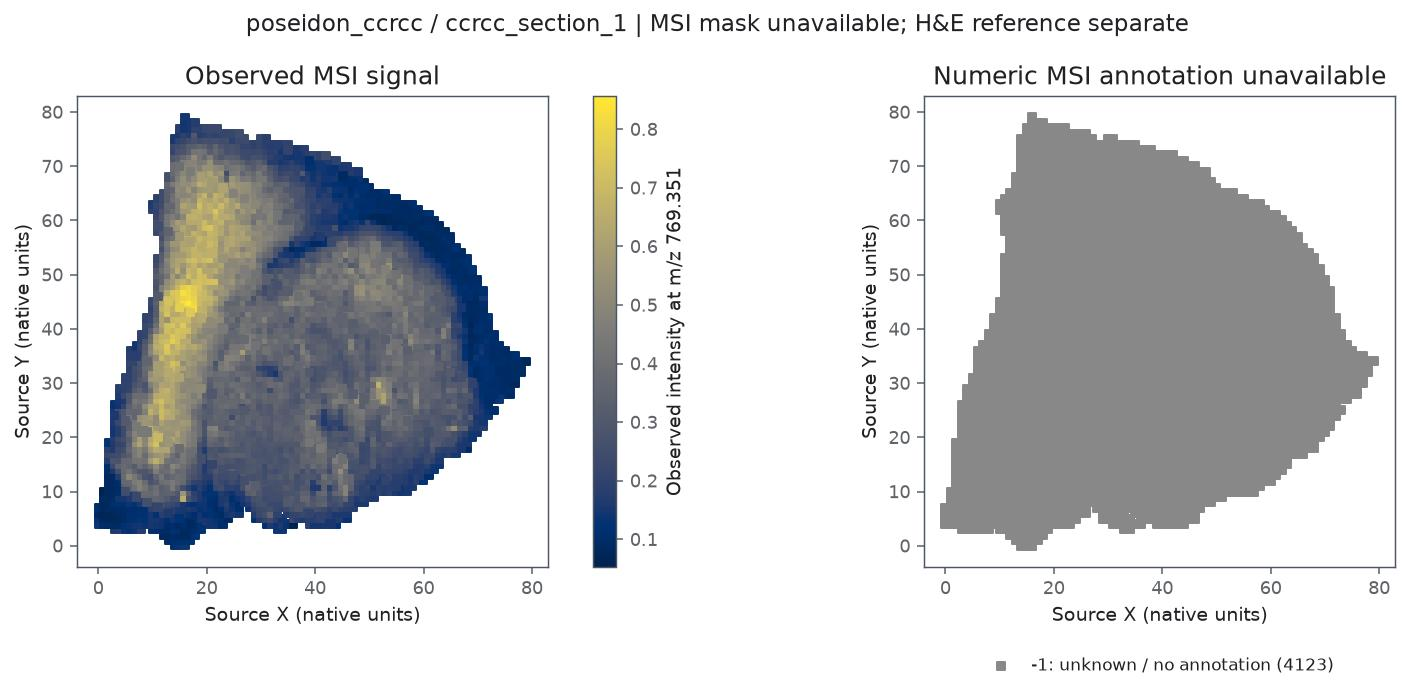

### cardinal_rcc

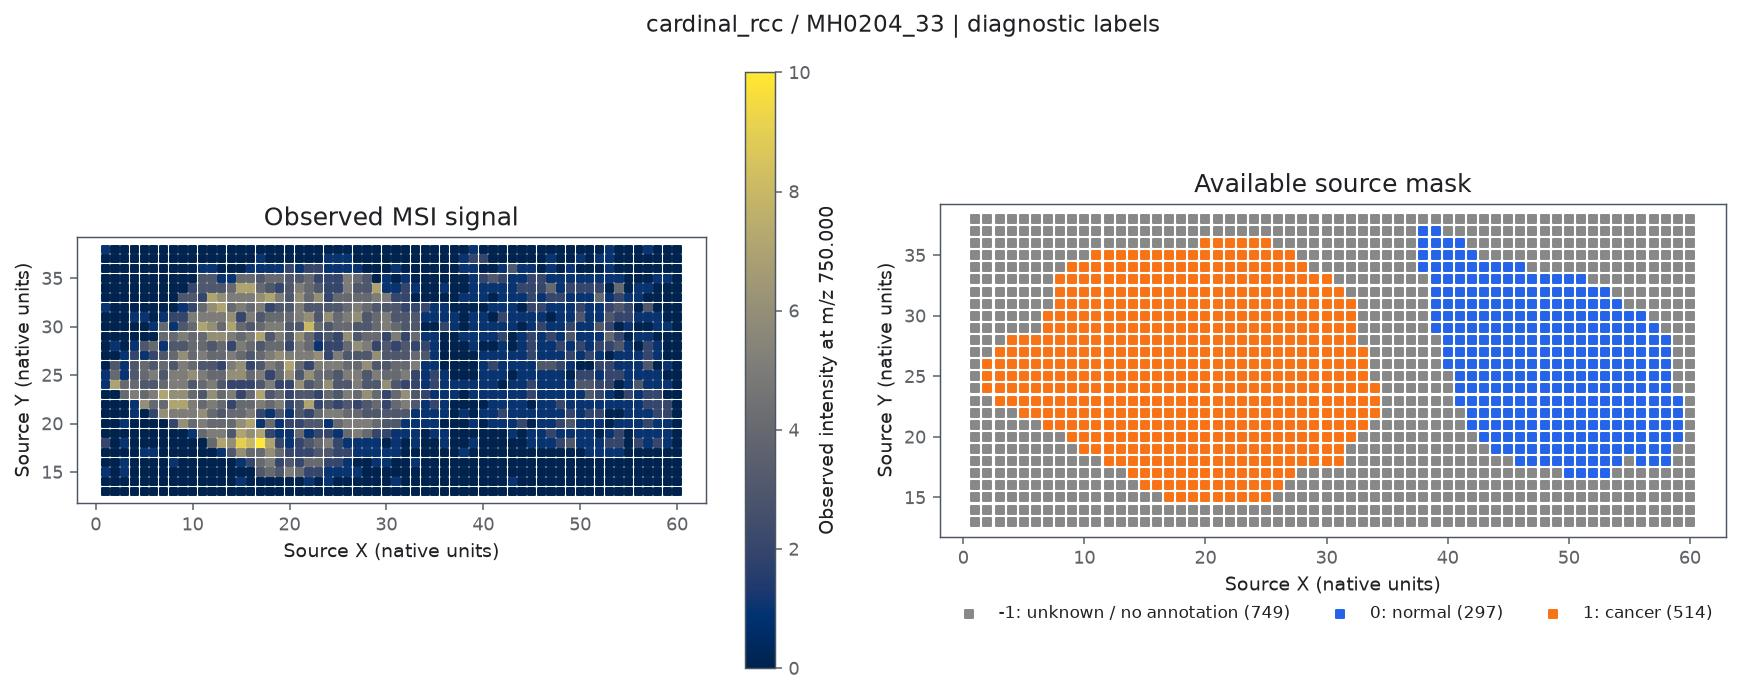

### blocksam_kidney

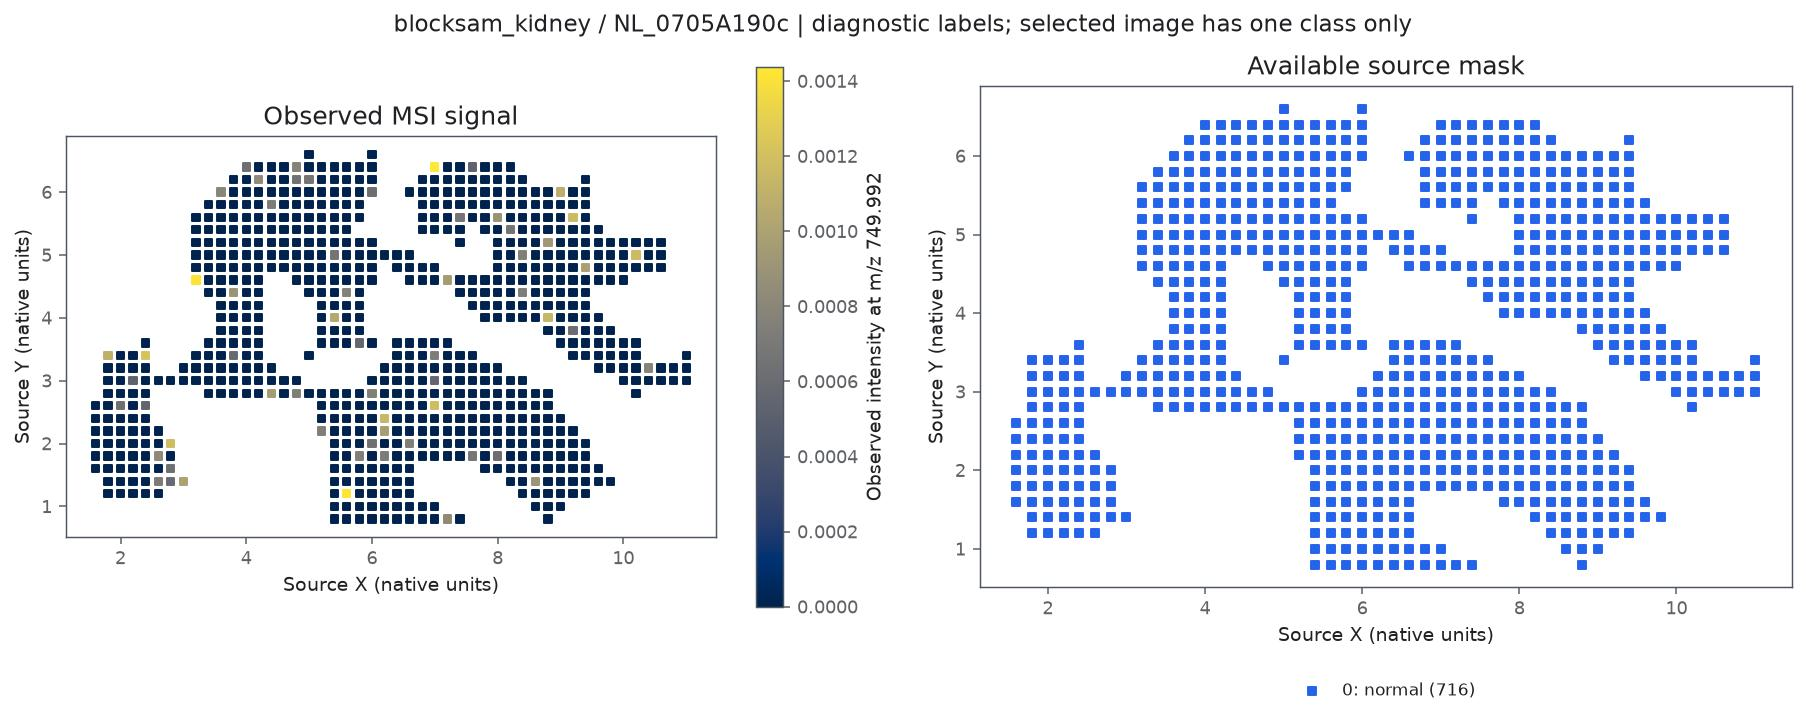

In [4]:
DATASET_IDS = [item["dataset_id"] for item in settings["datasets"]]
for dataset_id in DATASET_IDS:
    display(Markdown(f"### {dataset_id}"))
    display(Image(filename=str(results / "plots" / f"reference_dataset_{dataset_id}.jpeg")))

## Results / Summary

### LLM

Three source adapters produced canonical indexed images. The H&E mask preserves six classes and explicit unknown pixels. No mask-to-MSI correspondence or encoder input compatibility has been established; no anatomical model ranking is justified yet.

### Person